# ML미니과제1 다이아몬드 가격 예측

[] 노트북 한개로 M1부터 M5까지 순서대로 진행 미션마다 마크다운 셸로 제목 달고 미션의 생각해본 질문 답을 같은 마크다운 셸에 적기       
[] 무작위가 들어가는 곳은 모두 random_start=42로 고정      
[] 각 미션 힌트는 막혔을때만. 확인용 기준값은 다 하고 펴기. 정답코드없음. 수업노트북 다시 찾아보는게 좋은 힌트. 

## M1 데이터 불러오기
> 목표: diamonds 데이터를 내려받아 크기, 자료형, 기초 통계를 확인한다 

[O] mini-diamond 프로젝트를 만들고 scikit-learn, pandas, numpy, matplotlib, seaborn, ipykernel을 설치     
[O] 노트북 첫 셀에 import와 한글 폰트 설정을 넣는다(1장 2강 Lab7 셸 재사용)     
[O] sns.load_dataset("diamonds")로 불러와 df에 담고, 크기와 앞 5행을 본다       
[O] 각 열의 자료형과 빈칸 개수를 확인한다        
[X] 숫자 열의 기초 통계를 보고 이상해 보이는 값을 두 가지 이상 찾아 적는다      

- 생각해볼 질문: price의 평균과 중앙값 중 어느 쪽이 더 큰가요? 그 차이는 가격 분포에 대해 무엇을 말해 주나요? 
- 답: price는 평균이 더 큽니다. 중앙값보다 평균값이 더 높으니까 뭔가 튀는 값이 있는것같습니다. 

In [1]:
import platform
import matplotlib.pyplot as plt
import seaborn as sns

os_name = platform.system()
plt.rcParams["font.family"] = "Malgun Gothic"

df = sns.load_dataset("diamonds")
# print(df.shape)
# df.head()
# df.shape
# df.info()
# df.describe()
print("평균:", round(df["price"].mean(), 2), "| 중앙값:", df["price"].median())
# mean_price = df["price"].mean()
# df.loc[:, "price"] = df["price"].fillna(mean_price)
# print("남은 빈칸:", df["price"].isnull().sum())
# df.loc[empty_price, ["sex", "age", "class"]].head()

평균: 3932.8 | 중앙값: 2401.0


## M2 이상치 정리
> 목표: 말이 안 되는 값을 찾아 근거와 함께 제거하고 정리된 표 clean을 만든다 

[O] x, y, z 각각 0인 값이 몇 개인지 센다          
[] 셋 중 하나라도 0인 행이 몇 개인지 세고, 그 행들을 직접 본다          
[] y나 z가 20mm를 넘는 행을 찾아 직접 본다 왜 이상한 값이라고 판단할 수 있는지 적는다       
[] 두 종류의 이상한 행을 모두 뺀 clean 표를 만들고 제거 전후 행 수를 출력한다       

- 생각해 볼 질문: 어떤 행을 왜 지웠나요? 비싼 다이아몬드는 왜 지우면 안 되나요? 
- 답: 

In [3]:
cols = ['x', 'y', 'z']

zero_counts = (df[cols] == 0).sum()
print(zero_counts)

x     8
y     7
z    20
dtype: int64


## M3 그래프와 상관계수
> 목표: 가격의 분포와 무게-가격 관계를 그리고, 가격을 예측할 특성 하나를 고른다 

[] price의 히스토그램을 그리고 평균, 중앙값을 세로선으로 표시한다          
[] carat과 price의 산점도를 그린다(점이 많으면 3,000개만 무작위로 뽑아 그린다)           
[] 숫자 열끼리 상관계수를 구해 price와 상관이 큰 순서로 정렬한다        
[] 가격 예측에 쓸 특성 하나를 고르고 이유를 적는다        

- 생각해 볼 질문: 왜 carat을 (또는 다른 열을) 골랐나요? 산점도에서 직선 하나로 맞추기 어려워 보이는 부분은 어디인가요? 
- 답: 

<function matplotlib.pyplot.show(close=None, block=None)>

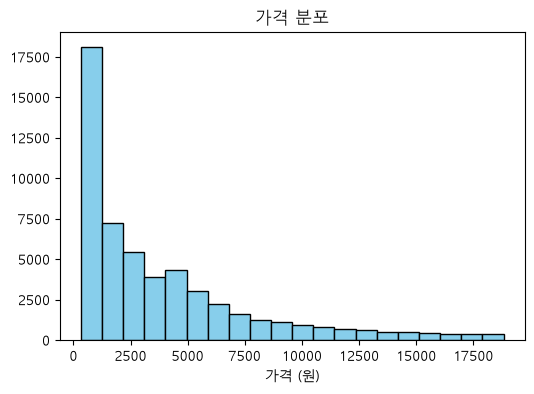

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(df["price"], bins=20, color="skyblue", edgecolor="black")
ax.set_title("가격 분포")
ax.set_xlabel("가격 (원)")
plt.show

## M4 무게로 가격 예측
> 목표: carat 하나로 선형 회귀를 학습해 w.b의 뜻을 설명하고, 새 다이아몬드의 가격을 예측하고, 직선을 그림으로 확인한다

[] X_train의 carat 열 하나로 LinearRegression을 학습하고 w(기울기), b(절편)를 출력한다     
[] w의 뜻을 한 문장으로 적는다("뭭가 1캐럿 늘면...")          
[] 0.25, 0.5, 1.0, 2.0 캐럿 다이아몬드의 가격을 예측한다. 이상한 결과가 있나?         
[] 학습 데이터 3,000개의 산점도에 찾은 직선(빨강)과 학습 데이터의 평균 가격(회색 가로선)을 겹쳐 그린다      

- 생각해볼 질문: 0.25 캐럿 다이아몬드의 예상가가 음수인 이유는 무엇일까요? 직선이 실제 점들보다 아래 위로 지나가는 구간은 각각 어디인가요? 평균 가격 가로선과 비교하면 직선은 무엇이 나아졌나요? 
- 답: 

## M5 특성 하나씩 직선 만들기
> 목표: 숫자 6개 열 각각 하나로 직선을 만들어 그림으로 비교하고 가격을 예측할 열을 고른 이유를 설명한다 

[] 숫자 6개 열 각각 하나로 LinearRegression을 학습한다         
[] 학습 데이터 3,000개의 산점도와 각 열의 직선을 2행 3열 그림 한 장에 그린다        
[] 직선이 점들을 잘 따라가는 열과 못 따라가는 열을 적는다          
[] 열마다 w(기울기)와 열의 범위(가장 작은 값~가장 큰 값)를 표 하나로 정리하고 w가 크면 더 좋은 열인지 생각해 적는다          
[] M3의 상관계수 순서와 그림이 같은 이야기를 하는지 확인한다         

- 답: 